# 02 · Drop-off diagnostics and product decision
**Synthetic portfolio case study · no measured business uplift**

Decision: which first-game friction merits a focused engineering investigation and controlled test? We separate the largest funnel loss from the strongest actionable diagnosis, quantify uncertainty, examine mix effects, and design a feasible experiment.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import norm
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
assert (ROOT/'data/raw/manifest.json').exists(), 'Run from the project root or notebooks folder.'
EXPORT = ROOT/'data/dashboard_exports'
FIG = ROOT/'dashboards/screenshots'
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 18)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', palette=['#635bff','#15a89c','#f1a43c','#e56b6f'])
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False,'axes.spines.right':False})
def table(name):
    return pd.read_csv(EXPORT/f'{name}.csv', dtype={'signup_app_version':str,'app_version':str})
def savefig(name):
    plt.savefig(FIG/f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
def wilson(k,n,z=1.959963984540054):
    k=np.asarray(k,dtype=float); n=np.asarray(n,dtype=float)
    p=k/n; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    radius=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return center-radius,center+radius
manifest=json.loads((ROOT/'data/raw/manifest.json').read_text())
cutoff=pd.Timestamp(manifest['observation_end_exclusive'])


In [2]:
a=table('user_activation')
a['signup_at']=pd.to_datetime(a.signup_at,utc=True)
for col in ['activated','activation_eligible','d7_eligible']:
    a[col]=a[col].astype(str).str.lower().isin(['true','t'])
a['d7_returned']=a.d7_returned.map(lambda x: np.nan if pd.isna(x) else int(str(x).lower() in ['true','t']))
eligible=a[a.activation_eligible].copy()
funnel=table('overall_funnel').sort_values('stage_order')
segments=table('segment_funnels')
attempts=table('first_day_attempts')
attempts['queue_entered_at']=pd.to_datetime(attempts.queue_entered_at,utc=True)


## 1. Funnel baseline and uncertainty
The numerator is unique users following a valid ordered path within 24 hours. The baseline interval is user-level Wilson 95%; it represents simulation sampling variation, not a claim about real product performance.

**Activation: 4,482/9,897 = 45.29%** (95% Wilson interval 44.31%–46.27%).

,stage,users,lost_users,step_conversion,cumulative_conversion
0,Sign-up,9897,NaN,NaN,1.0000
1,Onboarding completed,8464,"1,433.0000",0.8552,0.8552
2,Lobby viewed,8082,382.0000,0.9549,0.8166
3,Game joined,5896,"2,186.0000",0.7295,0.5957
4,Game started,5375,521.0000,0.9116,0.5431
5,Game completed,4482,893.0000,0.8339,0.4529


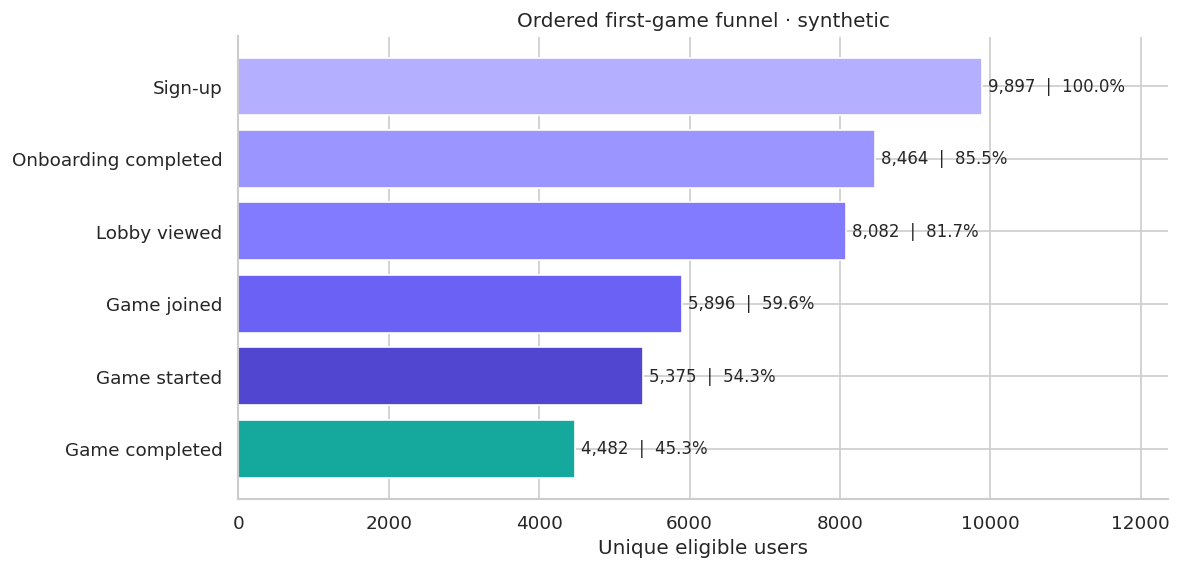

In [3]:
n=len(eligible); k=int(eligible.activated.sum()); lo,hi=wilson(k,n)
display(Markdown(f'**Activation: {k:,}/{n:,} = {k/n:.2%}** (95% Wilson interval {lo:.2%}–{hi:.2%}).'))
display(funnel[['stage','users','lost_users','step_conversion','cumulative_conversion']])
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(funnel.stage,funnel.users,color=['#b4b0ff','#9b95ff','#837bff','#6c61f5','#5146cf','#15a89c'])
for i,row in enumerate(funnel.itertuples()):ax.text(row.users+80,i,f'{row.users:,}  |  {row.cumulative_conversion:.1%}',va='center',fontsize=10)
ax.invert_yaxis();ax.set(xlim=(0,n*1.25),xlabel='Unique eligible users',title='Ordered first-game funnel · synthetic')
savefig('04_activation_funnel')


## 2. Separate absolute losses from conditional conversion
A high percentage loss in a tiny segment may matter less than a moderate loss across a large population. Funnel losses are mutually exclusive by furthest stage; segment losses overlap.

In [4]:
losses=funnel.dropna(subset=['lost_users']).sort_values('lost_users',ascending=False).copy()
losses['share_of_nonactivated']=losses.lost_users/(n-k)
display(losses[['stage','lost_users','step_dropoff','share_of_nonactivated']])
assert int(losses.lost_users.sum())==n-k
largest=losses.iloc[0]
display(Markdown(f'The largest absolute loss is before **{largest.stage}**: **{int(largest.lost_users):,} users**, or **{largest.share_of_nonactivated:.1%}** of all non-activated users. This identifies a location, not a cause.'))


,stage,lost_users,step_dropoff,share_of_nonactivated
3,Game joined,"2,186.0000",0.2705,0.4037
1,Onboarding completed,"1,433.0000",0.1448,0.2646
5,Game completed,893.0000,0.1661,0.1649
4,Game started,521.0000,0.0884,0.0962
2,Lobby viewed,382.0000,0.0451,0.0705


The largest absolute loss is before **Game joined**: **2,186 users**, or **40.4%** of all non-activated users. This identifies a location, not a cause.

## 3. Segment rates with sample sizes and confidence intervals
Show counts with rates. These are exploratory comparisons, not a family of pre-registered hypothesis tests; do not select a winner by the smallest p-value.

,dimension,segment,eligible_users,activated_users,activation_rate,ci_low,ci_high
0,version_device,1.0 / mid,2880,1381,0.4795,0.4613,0.4978
1,device,high,2222,1039,0.4676,0.4469,0.4884
2,version_device,1.1 / high,811,388,0.4784,0.4442,0.5128
3,channel,paid_social,3371,1279,0.3794,0.3632,0.3959
4,version,1.0,6167,2854,0.4628,0.4504,0.4752
5,version_device,1.1 / mid,1732,821,0.4740,0.4506,0.4976
6,channel,referral,1888,978,0.5180,0.4955,0.5405
7,channel,organic,3159,1536,0.4862,0.4688,0.5037
8,device,low,3063,1241,0.4052,0.3879,0.4227
9,version,1.1,3730,1628,0.4365,0.4206,0.4524


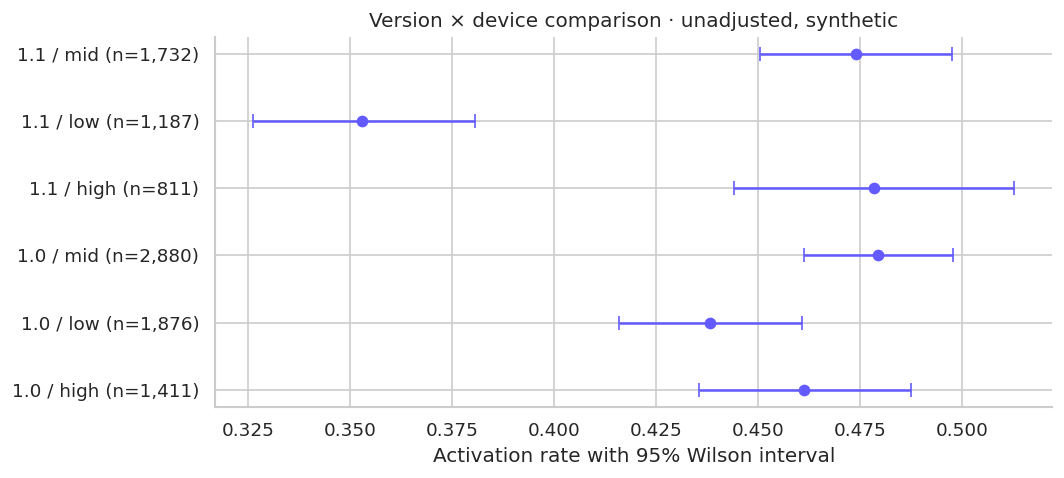

In [5]:
segments['ci_low'],segments['ci_high']=wilson(segments.activated_users,segments.eligible_users)
display(segments[['dimension','segment','eligible_users','activated_users','activation_rate','ci_low','ci_high']])
v=segments[segments.dimension.eq('version_device')].sort_values('segment')
fig,ax=plt.subplots(figsize=(9,4))
ax.errorbar(v.activation_rate,np.arange(len(v)),xerr=[v.activation_rate-v.ci_low,v.ci_high-v.activation_rate],fmt='o',color='#635bff',capsize=4)
ax.set_yticks(np.arange(len(v)),[f'{r.segment} (n={r.eligible_users:,})' for r in v.itertuples()])
ax.set(xlabel='Activation rate with 95% Wilson interval',title='Version × device comparison · unadjusted, synthetic')
savefig('05_version_device_activation')


## 4. Decompose the lobby-to-join loss
A lobby user may never request a match, or may request one but not join. A single funnel bar cannot tell these mechanisms apart. Count both populations before proposing a queue change.

In [6]:
lobby=eligible[eligible.furthest_stage.ge(3)].copy()
lobby['join_status']=np.select([lobby.furthest_stage.ge(4),lobby.attempts_24h.eq(0)],['Joined a game','No matchmaking attempt'],default='Attempted but did not join')
lobby_breakdown=lobby.join_status.value_counts().rename_axis('status').to_frame('users')
lobby_breakdown['share_of_lobby']=lobby_breakdown.users/len(lobby)
display(lobby_breakdown)
nonjoin=lobby[lobby.furthest_stage.eq(3)]
display(pd.crosstab(nonjoin.device_tier,nonjoin.join_status))


,users,share_of_lobby
status,,
Joined a game,5896,0.7295
No matchmaking attempt,1207,0.1493
Attempted but did not join,979,0.1211


join_status,Attempted but did not join,No matchmaking attempt
device_tier,,
high,207,275
low,367,373
mid,405,559


## 5. Diagnose failures using the first attempt per user
Repeated attempts inflate the apparent sample size. The table below uses one attempt per user, restricts registration to the concurrent version period, and separates device tiers. Failure codes provide a concrete engineering lead.

In [7]:
first=attempts[attempts.attempt_number.eq(1)].merge(a[['user_id','signup_at']],on='user_id',validate='one_to_one')
first=first[first.signup_at.ge(pd.Timestamp('2026-02-15T00:00Z'))].copy()
first['failed']=first.outcome.eq('failed')
first_failure=first.groupby(['app_version','device_tier']).agg(users=('user_id','size'),failed_users=('failed','sum'))
first_failure['failure_rate']=first_failure.failed_users/first_failure.users
first_failure['ci_low'],first_failure['ci_high']=wilson(first_failure.failed_users,first_failure.users)
display(first_failure)
display(attempts[attempts.outcome.eq('failed')].groupby(['app_version','device_tier','failure_reason']).size().to_frame('failed_attempts'))
first_failure.reset_index().to_csv(EXPORT/'first_attempt_failure.csv',index=False)


users  failed_users  failure_rate  ci_low  ci_high
app_version device_tier                                                    
1.0         high           190             4        0.0211  0.0082   0.0529
            low            261             7        0.0268  0.0131   0.0543
            mid            366             4        0.0109  0.0043   0.0278
1.1         high           573            12        0.0209  0.0120   0.0362
            low            815           153        0.1877  0.1624   0.2160
            mid           1232            18        0.0146  0.0093   0.0230

failed_attempts
app_version device_tier failure_reason                 
1.0         high        network_error                30
            low         network_error                48
            mid         network_error                46
1.1         high        network_error                12
            low         client_timeout              241
            mid         network_error                25

## 6. Control observable mix: concurrent week × channel standardisation
Within each device tier, compare version 1.1 and 1.0 in the same signup weeks and channels. Keep only strata containing both versions; weight each stratum by its pooled eligible-user count. Report coverage, because common-support exclusions can change the population.

This is descriptive adjustment. It does not control latent intent, prove a version effect, or replace randomisation.

In [8]:
strata=table('version_strata')
adjusted=[]
for tier,d in strata.groupby('device_tier'):
    counts=d.pivot(index=['signup_week','acquisition_channel'],columns='signup_app_version',values='eligible_users')
    success=d.pivot(index=['signup_week','acquisition_channel'],columns='signup_app_version',values='activated_users')
    keep=counts[['1.0','1.1']].notna().all(axis=1)
    counts=counts.loc[keep];success=success.loc[keep]
    w=counts.sum(axis=1)/counts.values.sum(); rates=success/counts
    p0=float((w*rates['1.0']).sum());p1=float((w*rates['1.1']).sum())
    se=float(np.sqrt(((w**2)*(rates['1.0']*(1-rates['1.0'])/counts['1.0']+rates['1.1']*(1-rates['1.1'])/counts['1.1'])).sum()))
    adjusted.append({'device_tier':tier,'standardised_v10':p0,'standardised_v11':p1,'difference_pp':100*(p1-p0),'ci_low_pp':100*(p1-p0-1.96*se),'ci_high_pp':100*(p1-p0+1.96*se),'shared_strata':len(counts),'covered_users':int(counts.values.sum()),'coverage':float(counts.values.sum()/d.eligible_users.sum())})
adjusted=pd.DataFrame(adjusted)
display(adjusted)
adjusted.to_csv(EXPORT/'standardised_version_comparison.csv',index=False)


,device_tier,standardised_v10,standardised_v11,difference_pp,ci_low_pp,ci_high_pp,shared_strata,covered_users,coverage
0,high,0.5037,0.4832,-2.0467,-8.7314,4.6380,27,1060,0.9815
1,low,0.4549,0.3534,-10.1526,-15.7145,-4.5908,31,1563,0.9968
2,mid,0.4495,0.4743,2.4787,-2.2234,7.1807,31,2271,0.9978


## 7. Waiting-time bands: competing outcomes, not a causal dose-response
Observed wait ends when a user matches, abandons, or encounters a failure. Long-wait groups select users who remained in the queue. A chart cannot establish that reducing waiting time by a given amount would cause a particular activation gain.

,wait_band,attempts,users,join_rate,abandonment_rate,failure_rate
0,01. <15s,4101,3580,0.7844,0.1502,0.0653
1,02. 15-29s,2855,2576,0.6935,0.2595,0.0469
2,03. 30-59s,1875,1745,0.7216,0.2784,0.0000
3,04. 60s+,555,539,0.7153,0.2847,0.0000


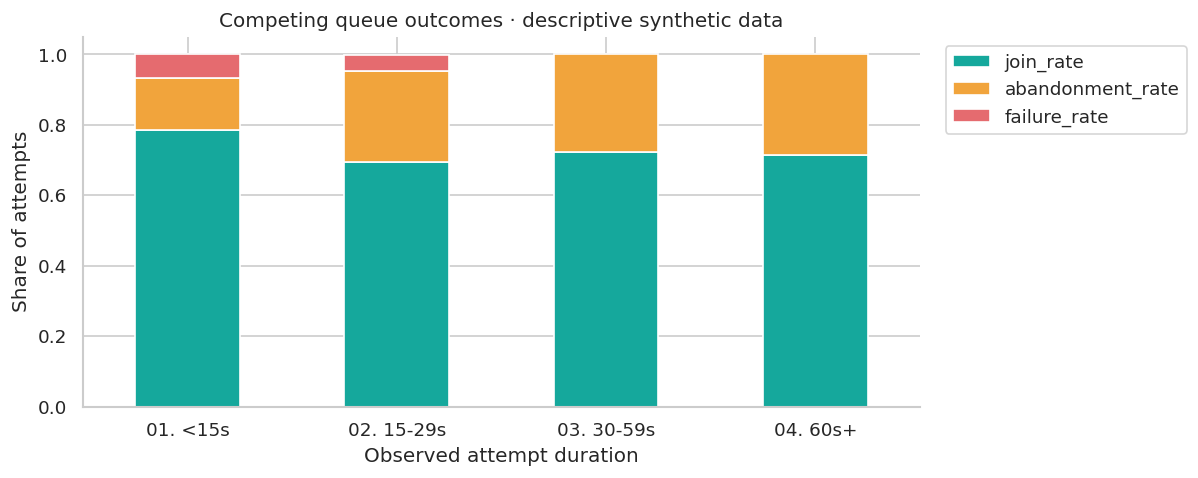

In [9]:
wait=table('wait_outcomes').sort_values('wait_band')
display(wait)
fig,ax=plt.subplots(figsize=(9,4))
wait.set_index('wait_band')[['join_rate','abandonment_rate','failure_rate']].plot.bar(stacked=True,ax=ax,color=['#15a89c','#f1a43c','#e56b6f'])
ax.set(xlabel='Observed attempt duration',ylabel='Share of attempts',title='Competing queue outcomes · descriptive synthetic data')
ax.tick_params(axis='x',rotation=0);ax.legend(bbox_to_anchor=(1.02,1));savefig('06_wait_outcomes')


## 8. Retry recovery and repeated-attempt bias
A failed first attempt does not mean a lost user. Some users retry and activate. Recovery is observed behaviour, not evidence that prompting a retry will cause the same recovery rate.

In [10]:
recovery=table('retry_recovery')
recovery['retry_rate']=recovery.retry_users/recovery.users
display(recovery)
all_failure=attempts.outcome.eq('failed').mean()
first_failure_all=attempts.loc[attempts.attempt_number.eq(1),'outcome'].eq('failed').mean()
print(f'All-attempt failure rate: {all_failure:.2%}; first-attempt user rate: {first_failure_all:.2%}.')


All-attempt failure rate: 4.28%; first-attempt user rate: 4.01%.


,first_outcome,users,retry_users,activated_users,activation_rate,retry_rate
0,abandoned,1465,790,478,0.3263,0.5392
1,failed,276,153,93,0.3370,0.5543
2,joined,5134,1141,3911,0.7618,0.2222


## 9. Activation timing and horizon sensitivity
Median activation time describes successful users only. The cumulative-incidence table uses all eligible registrations and reveals how much activation happens after the first hour.

,acquisition_channel,activated_users,median_minutes,p90_minutes,mean_minutes
0,influencer,689,12.5377,670.5994,140.6959
1,organic,1536,12.1529,592.3826,129.3661
2,paid_social,1279,12.3896,629.8931,135.0444
3,referral,978,12.3631,624.7195,130.5838


,minutes,eligible_users,activated_by_horizon,activation_rate
0,15,9897,3013,0.3044
2,60,9897,3626,0.3664
1,360,9897,3844,0.3884
3,1440,9897,4482,0.4529


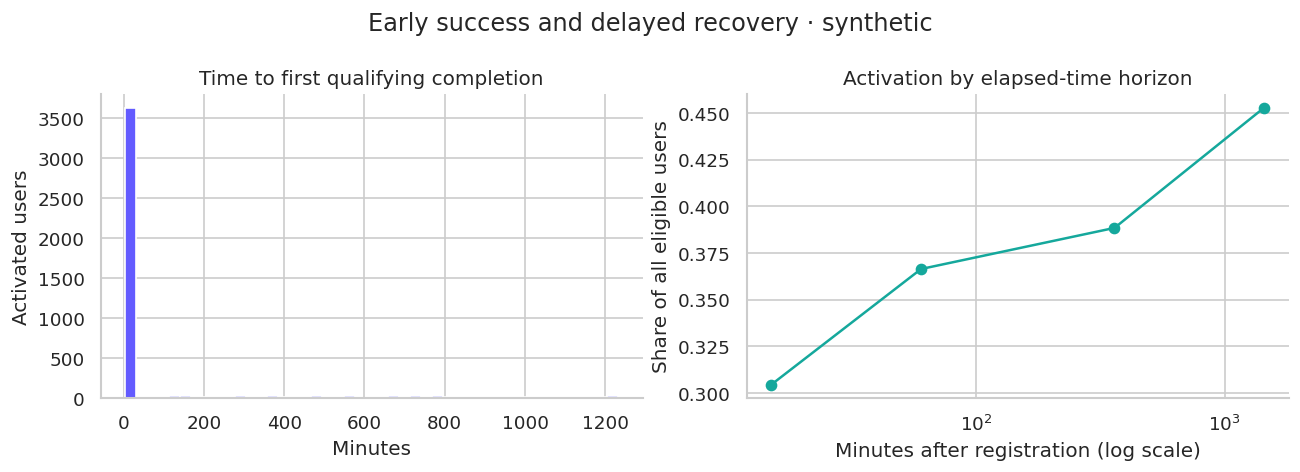

In [11]:
timing=table('activation_timing');horizons=table('activation_horizons').sort_values('minutes')
display(timing);display(horizons)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(eligible.loc[eligible.activated,'time_to_activation_minutes'],bins=45,color='#635bff')
axes[0].set(xlabel='Minutes',ylabel='Activated users',title='Time to first qualifying completion')
axes[1].plot(horizons.minutes,horizons.activation_rate,marker='o',color='#15a89c');axes[1].set_xscale('log')
axes[1].set(xlabel='Minutes after registration (log scale)',ylabel='Share of all eligible users',title='Activation by elapsed-time horizon')
fig.suptitle('Early success and delayed recovery · synthetic');fig.tight_layout();savefig('07_activation_timing')


## 10. Activation and D7 return: association with confounding
First-day activation is measured before D7, avoiding use of future activity to define the early group. However, motivation affects both outcomes in the generator. Do not say activation caused higher retention.

,activated,eligible_users,returning_users,d7_retention,ci_low,ci_high
0,False,5051,962,0.1905,0.1799,0.2015
1,True,4212,893,0.2120,0.1999,0.2246


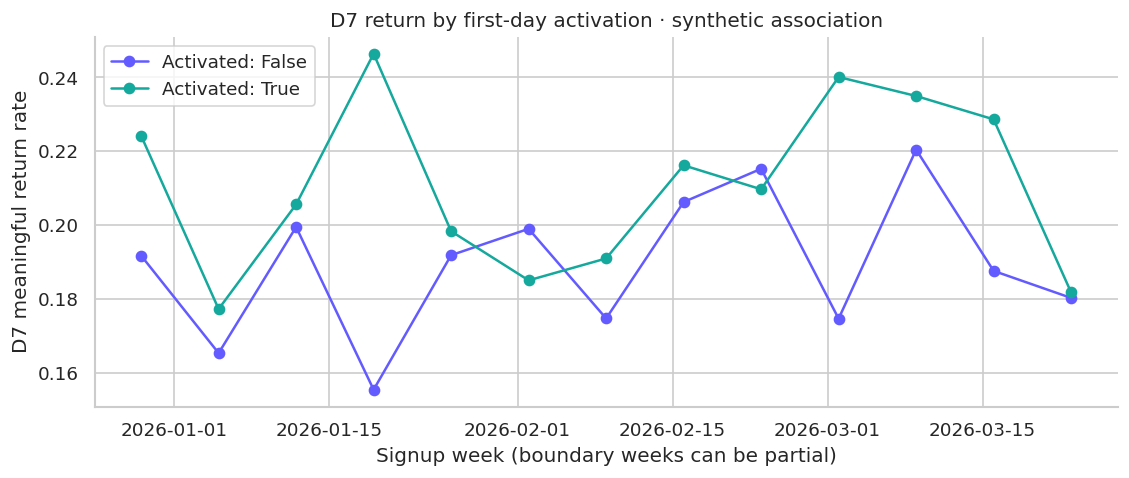

In [12]:
ret=table('retention_comparison')
ret['ci_low'],ret['ci_high']=wilson(ret.returning_users,ret.eligible_users)
display(ret)
coh=table('retention_cohorts');coh['signup_week']=pd.to_datetime(coh.signup_week)
fig,ax=plt.subplots(figsize=(11,4))
for group,part in coh.groupby('activated'):
    part=part.sort_values('signup_week');ax.plot(part.signup_week,part.d7_retention,marker='o',label=f'Activated: {group}')
ax.set(xlabel='Signup week (boundary weeks can be partial)',ylabel='D7 meaningful return rate',title='D7 return by first-day activation · synthetic association')
ax.legend();savefig('08_retention_cohorts')


## 11. Check whether the retention association survives observable segmentation
Compare first-day activation groups within channel × device tier. Small cells can vary substantially. Even a consistent adjusted association would not eliminate the deliberately unmeasured intent variable.

In [13]:
rseg=table('retention_segments')
wide=rseg.pivot(index=['acquisition_channel','device_tier'],columns='activated',values='d7_retention')
display(wide)
ret_eligible=a[a.activation_eligible & a.d7_eligible]
ret_gap=float(ret_eligible.loc[ret_eligible.activated,'d7_returned'].mean()-ret_eligible.loc[~ret_eligible.activated,'d7_returned'].mean())
print(f'Unadjusted D7 difference: {ret_gap*100:.2f} percentage points; descriptive only.')


Unadjusted D7 difference: 2.16 percentage points; descriptive only.


activated                        False  True 
acquisition_channel device_tier              
influencer          high        0.1878 0.2727
                    low         0.1878 0.2483
                    mid         0.1937 0.1802
organic             high        0.1980 0.1792
                    low         0.2190 0.2113
                    mid         0.2217 0.2288
paid_social         high        0.1523 0.2074
                    low         0.1401 0.1507
                    mid         0.1740 0.1758
referral            high        0.2238 0.2381
                    low         0.2120 0.2243
                    mid         0.2376 0.2842

## 12. Prioritisation and bounded opportunity scenarios
Use the low-tier version 1.1 population as a concrete investigation target if the failure pattern supports it. The gap to standardised version 1.0 is an **observational benchmark**, not an attainable causal gain. Evaluate partial gap closure rather than presenting all non-activated users as recoverable.

In [14]:
target=eligible[(eligible.device_tier=='low') & (eligible.signup_app_version=='1.1')]
low_adj=adjusted.set_index('device_tier').loc['low']
gap=max(0,float(low_adj.standardised_v10-low_adj.standardised_v11))
scenarios=pd.DataFrame({'share_of_observed_gap_closed':[.25,.5,1.]})
scenarios['scenario_activation_change_pp']=scenarios.share_of_observed_gap_closed*gap*100
scenarios['scenario_additional_activated_users']=scenarios.share_of_observed_gap_closed*gap*len(target)
display(scenarios)
print(f'Target population: {len(target):,} users. These are counterfactual scenarios, not forecasts or achieved results.')
scenarios.to_csv(EXPORT/'opportunity_scenarios.csv',index=False)


Target population: 1,187 users. These are counterfactual scenarios, not forecasts or achieved results.


,share_of_observed_gap_closed,scenario_activation_change_pp,scenario_additional_activated_users
0,0.2500,2.5382,30.1279
1,0.5000,5.0763,60.2558
2,1.0000,10.1526,120.5117


## 13. Experiment sizing and operational feasibility
Propose a client-side reliability fix behind a remote flag. Randomise low-tier version 1.1 registrations 50:50 before exposure; retain assignment across sessions. The primary outcome is 24h activation on an intention-to-treat basis.

Assume a 5-percentage-point absolute minimum detectable effect, 80% power, and two-sided α=0.05. This planning assumption is not the observed gap. The approximate two-proportion sample size uses independent users, not attempts.

In [15]:
p0=float(target.activated.mean());delta=.05;p1=min(p0+delta,.99);pbar=(p0+p1)/2
zalpha=norm.ppf(.975);zpower=norm.ppf(.8)
n_arm=int(np.ceil(((zalpha*np.sqrt(2*pbar*(1-pbar))+zpower*np.sqrt(p0*(1-p0)+p1*(1-p1)))**2)/(p1-p0)**2))
rollout_days=(cutoff-pd.Timestamp('2026-02-15T00:00Z')).total_seconds()/86400-1
arrivals=len(target)/rollout_days
collection_days=int(np.ceil(2*n_arm/arrivals))
plan={'baseline':p0,'mde_absolute':delta,'power':.8,'alpha_two_sided':.05,'users_per_arm':n_arm,'total_users':2*n_arm,'observed_target_users_per_day':arrivals,'estimated_enrolment_days':collection_days,'activation_followup_days':1,'d7_followup_up_to_days':8}
display(pd.DataFrame([plan]).T.rename(columns={0:'value'}))
print('Do not promise a two-week test if target traffic cannot support the required sample.')


Do not promise a two-week test if target traffic cannot support the required sample.


,value
baseline,0.3530
mde_absolute,0.0500
power,0.8000
alpha_two_sided,0.0500
users_per_arm,"1,476.0000"
total_users,"2,952.0000"
observed_target_users_per_day,26.9773
estimated_enrolment_days,110.0000
activation_followup_days,1.0000
d7_followup_up_to_days,8.0000


## 14. Save decision evidence and dashboard inputs
These exports retain numerators and denominators for transparent reporting. The decision memo interprets them; it does not assert that an experiment has already run.

In [16]:
segments.to_csv(EXPORT/'segment_rates_with_intervals.csv',index=False)
ret.to_csv(EXPORT/'retention_with_intervals.csv',index=False)
summary={'synthetic':True,'users':len(a),'eligible_users':n,'activated_users':k,'activation_rate':k/n,'activation_ci':[float(lo),float(hi)],'d7_eligible_users':int(a.d7_eligible.sum()),'largest_loss_stage':str(largest.stage),'largest_loss_users':int(largest.lost_users),'target_users':len(target),'target_activation_rate':p0,'standardised_low_tier_gap_pp':float(low_adj.difference_pp),'retention_gap_pp':ret_gap*100,'experiment':plan}
(ROOT/'data/processed/analysis_summary.json').write_text(json.dumps(summary,indent=2))
display(Markdown('**Recommendation:** investigate the version/device-specific client failure pathway, verify it with production telemetry, and test the smallest reliability fix. Keep lobby discovery and acquisition-intent questions as separate workstreams.'))


**Recommendation:** investigate the version/device-specific client failure pathway, verify it with production telemetry, and test the smallest reliability fix. Keep lobby discovery and acquisition-intent questions as separate workstreams.

## Limitations and next data requests
1. Synthetic relationships are intentionally generated; they are not independent evidence about Tamasha.
2. Event telemetry alone cannot explain motivation. Add user interviews or usability sessions before redesigning onboarding.
3. Request crash/ANR traces, server request IDs and timeout codes to confirm a real client defect.
4. Request queue supply and room occupancy before making supply-side matchmaking recommendations.
5. Request experiment exposure/assignment events and stable device classification before testing.
6. The experiment is a proposal. No A/B result, business uplift, or causal retention improvement is claimed.
7. Statistical uncertainty shown here omits generator-model uncertainty and real-world selection processes.

## 15. Rebuild the Tableau package
The following cell generates the native workbook XML, three dashboards, nine worksheets and embedded CSV data. It validates ZIP contents and references. Native opening/rendering in Tableau remains a separate manual verification step; the delivered XML also passed the official XSD check recorded in `data/processed/tableau_validation.json`.

In [17]:
from pathlib import Path
from xml.etree import ElementTree as ET
import pandas as pd
import zipfile, json, uuid
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd()/'social-gaming-activation-analysis'
OUT=ROOT/'dashboards'; EX=ROOT/'data/dashboard_exports'

def E(parent,tag,text=None,**attrs):
    node=ET.SubElement(parent,tag,{k.replace('_','-'):str(v) for k,v in attrs.items()})
    if text is not None:node.text=str(text)
    return node

f=pd.read_csv(EX/'overall_funnel.csv').sort_values('stage_order')
w=pd.read_csv(EX/'weekly_activation.csv').sort_values('signup_week')
s=pd.read_csv(EX/'segment_funnels.csv')
fail=pd.read_csv(EX/'first_attempt_failure.csv',dtype={'app_version':str})
wait=pd.read_csv(EX/'wait_outcomes.csv').sort_values('wait_band')
h=pd.read_csv(EX/'activation_horizons.csv').sort_values('minutes')
ret=pd.read_csv(EX/'retention_comparison.csv')
coh=pd.read_csv(EX/'retention_cohorts.csv').sort_values('signup_week')
sources=[]
def chart(name,category,num,den,kind='rate'):
    df=pd.DataFrame({'Category':category.astype(str).to_numpy(),'Numerator':num.to_numpy(),'Denominator':den.to_numpy()})
    sources.append((name,df,kind))
chart('01 Ordered activation funnel',f.stage_order.astype(str)+' · '+f.stage,f.users,f.registered_users,'count')
chart('02 Weekly activation',w.signup_week,w.activated_users,w.eligible_users)
c=s[s.dimension.eq('channel')];chart('03 Activation by channel',c.segment,c.activated_users,c.eligible_users)
c=s[s.dimension.eq('version_device')];chart('04 Activation by version and device',c.segment,c.activated_users,c.eligible_users)
chart('05 First-attempt failure by version and device',fail.app_version+' / '+fail.device_tier,fail.failed_users,fail.users)
chart('06 Queue abandonment by observed wait',wait.wait_band,(wait.abandonment_rate*wait.attempts).round(),wait.attempts)
chart('07 Activation by elapsed-time horizon',h.minutes.astype(str)+' minutes',h.activated_by_horizon,h.eligible_users)
chart('08 D7 return by first-day activation',ret.activated.map({True:'Activated',False:'Not activated'}),ret.returning_users,ret.eligible_users)
chart('09 D7 cohort and activation group',coh.signup_week+' / '+coh.activated.map({True:'Activated',False:'Not activated'}),coh.returning_users,coh.eligible_users)

book=ET.Element('workbook',{'source-build':'20261.26.0211.1127','source-platform':'win','version':'18.1','original-version':'18.1','xmlns:user':'http://www.tableausoftware.com/xml/user'})
prefs=E(book,'preferences');E(prefs,'preference',name='ui.encoding.shelf.height',value='24');E(prefs,'preference',name='ui.shelf.height',value='26')
datasources=E(book,'datasources')
metadata=[]
for idx,(name,df,kind) in enumerate(sources):
    dsname=f'textscan.activation{idx+1}'
    filename=f'chart_{idx+1:02d}.csv'
    ds=E(datasources,'datasource',caption=name,inline='true',name=dsname,version='18.1')
    conn=E(ds,'connection',**{'class':'textscan','directory':'Data','filename':filename,'password':'','server':''})
    rel=E(conn,'relation',name=filename.replace('.','#'),table='['+filename.replace('.','#')+']',type='table')
    cols=E(rel,'columns',character_set='UTF-8',header='yes',locale='en_US',separator=',')
    records=E(conn,'metadata-records')
    definitions=[('Category','string','dimension','nominal'),('Numerator','real','measure','quantitative'),('Denominator','real','measure','quantitative')]
    for j,(col,dtype,role,typ) in enumerate(definitions):
        E(cols,'column',datatype=dtype,name=col,ordinal=j)
        rec=E(records,'metadata-record',**{'class':'column'})
        for tag,value in [('remote-name',col),('remote-type',129 if dtype=='string' else 5),('local-name',f'[{col}]'),('parent-name','['+filename.replace('.','#')+']'),('remote-alias',col),('ordinal',j),('local-type',dtype),('aggregation','Count' if role=='dimension' else 'Sum'),('contains-null','false')]:E(rec,tag,text=value)
    for col,dtype,role,typ in definitions:E(ds,'column',datatype=dtype,name=f'[{col}]',role=role,type=typ)
    metric=E(ds,'column',caption='Rate' if kind=='rate' else 'Users',datatype='real',name='[Metric]',role='measure',type='quantitative',default_format='p0.0%' if kind=='rate' else 'n0')
    E(metric,'calculation',**{'class':'tableau','formula':'SUM([Numerator])/SUM([Denominator])' if kind=='rate' else 'SUM([Numerator])'})
    metadata.append((name,dsname,filename,df,kind))
worksheets=E(book,'worksheets')
for name,dsname,filename,df,kind in metadata:
    ws=E(worksheets,'worksheet',name=name)
    table=E(ws,'table');view=E(table,'view');dslist=E(view,'datasources');E(dslist,'datasource',caption=name,name=dsname)
    deps=E(view,'datasource-dependencies',datasource=dsname)
    for col,dtype,role,typ in [('Category','string','dimension','nominal'),('Numerator','real','measure','quantitative'),('Denominator','real','measure','quantitative'),('Metric','real','measure','quantitative')]:
        node=E(deps,'column',datatype=dtype,name=f'[{col}]',role=role,type=typ)
        if col=='Metric':E(node,'calculation',**{'class':'tableau','formula':'SUM([Numerator])/SUM([Denominator])' if kind=='rate' else 'SUM([Numerator])'})
    E(deps,'column-instance',column='[Category]',derivation='None',name='[none:Category:nk]',pivot='key',type='nominal')
    E(deps,'column-instance',column='[Metric]',derivation='User',name='[usr:Metric:qk]',pivot='key',type='quantitative')
    E(view,'aggregation',value='true')
    style=E(table,'style');rule=E(style,'style-rule',element='mark');E(rule,'format',attr='mark-color',value='#635BFF')
    panes=E(table,'panes');pane=E(panes,'pane');pv=E(pane,'view');E(pv,'breakdown',value='auto');E(pane,'mark',**{'class':'Bar'})
    E(table,'rows',text=f'[{dsname}].[none:Category:nk]');E(table,'cols',text=f'[{dsname}].[usr:Metric:qk]')

for ws in worksheets: E(ws,'simple-id',uuid='{'+str(uuid.uuid5(uuid.NAMESPACE_DNS,ws.attrib['name'])).upper()+'}')

dboards=E(book,'dashboards')
pages=[('01 Activation overview · SYNTHETIC',[0,1,2]),('02 Friction diagnostics · SYNTHETIC',[3,4,5]),('03 Timing and retention · SYNTHETIC',[6,7,8])]
for title,indices in pages:
    dash=E(dboards,'dashboard',name=title);E(dash,'style');E(dash,'size',maxheight=1000,maxwidth=1400,minheight=1000,minwidth=1400)
    zones=E(dash,'zones');layout=E(zones,'zone',type_v2='layout-basic',h=100000,w=100000,x=0,y=0,id=0)
    for pos,idx in enumerate(indices):
        z=E(layout,'zone',h=32000,w=98000,x=1000,y=1000+pos*33000,id=pos+1,name=metadata[idx][0])
        st=E(z,'zone-style');E(st,'format',attr='border-style',value='none');E(st,'format',attr='margin',value='10')
for dash in dboards: E(dash,'simple-id',uuid='{'+str(uuid.uuid5(uuid.NAMESPACE_DNS,dash.attrib['name'])).upper()+'}')
windows=E(book,'windows',source_height='30')
for name,*_ in metadata:
    win=E(windows,'window',**{'class':'worksheet','name':name})
    cards=E(win,'cards');edge=E(cards,'edge',name='left');strip=E(edge,'strip',size='160')
    for kind in ['pages','filters','marks']:E(strip,'card',type=kind)
    edge=E(cards,'edge',name='top')
    for kind in ['columns','rows']:E(E(edge,'strip',size='2147483647'),'card',type=kind)
    E(E(win,'viewpoint'),'zoom',type='entire-view')
for title,indices in pages:
    win=E(windows,'window',**{'class':'dashboard','name':title,'maximized':'true'})
    viewpoints=E(win,'viewpoints')
    for idx in indices:E(E(viewpoints,'viewpoint',name=metadata[idx][0]),'zoom',type='entire-view')
for win in windows:
    if win.attrib['class']=='dashboard': E(win,'active',id='1')
E(E(book,'explain-data',enabled_for_viewer='false',extreme_values_enabled_for_all='false'),'explanation-types')
ET.indent(book,space='  ')
xml=ET.tostring(book,encoding='utf-8',xml_declaration=True)
with zipfile.ZipFile(OUT/'activation_dashboard.twbx','w',zipfile.ZIP_DEFLATED) as z:
    z.writestr('activation_dashboard.twb',xml)
    for name,dsname,filename,df,kind in metadata:z.writestr('Data/'+filename,df.to_csv(index=False))
# ZIP/structure and column integrity checks; native Tableau rendering is separate.
with zipfile.ZipFile(OUT/'activation_dashboard.twbx') as z:
    assert z.testzip() is None
    tree=ET.fromstring(z.read('activation_dashboard.twb'))
    assert len(tree.findall('./dashboards/dashboard'))==3
    assert len(tree.findall('./worksheets/worksheet'))==9
    for connection in tree.findall('./datasources/datasource/connection'):
        assert connection.attrib['directory']+'/'+connection.attrib['filename'] in z.namelist()
print('Packaged 3 Tableau dashboards, 9 worksheets and 9 embedded CSV sources.')


Packaged 3 Tableau dashboards, 9 worksheets and 9 embedded CSV sources.


## 16. Render the analytical dashboard previews
These are Python-rendered views of the same findings, not screenshots from Tableau Desktop. Their narrative callouts describe the bundled seed-2026 analysis; revise those callouts if changing the simulation.

In [18]:
from pathlib import Path
import pandas as pd,numpy as np,json
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
R=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd()/'social-gaming-activation-analysis';D=R/'data/dashboard_exports';O=R/'dashboards/screenshots'
s=json.loads((R/'data/processed/analysis_summary.json').read_text())
purple='#635bff';teal='#159b8f';orange='#d78a23';ink='#172338';muted='#66748b'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#d4dce6','axes.labelcolor':muted,'xtick.color':muted,'ytick.color':ink})
def canvas(title,subtitle,kpis):
 fig=plt.figure(figsize=(14,9),facecolor='#f3f5fa')
 fig.text(.05,.95,title,fontsize=25,fontweight='bold',color=ink)
 fig.text(.05,.915,subtitle,fontsize=11,color=muted)
 for i,(label,val) in enumerate(kpis):
  x=.05+i*.235
  fig.text(x,.855,val,fontsize=25,color=purple,fontweight='bold')
  fig.text(x,.823,label,fontsize=10,color=muted)
 fig.text(.05,.025,'SYNTHETIC DATA  |  Jan–Mar 2026  |  Python-rendered analytical preview; not a Tableau application screenshot',fontsize=9,color=muted)
 return fig
f=pd.read_csv(D/'overall_funnel.csv').sort_values('stage_order');weekly=pd.read_csv(D/'weekly_activation.csv').sort_values('signup_week');segments=pd.read_csv(D/'segment_funnels.csv')
fig=canvas('FIRST GAME / Activation overview','Where new users leave before completing their first game within 24 hours.', [('Eligible users',f'{s["eligible_users"]:,}'),('Activated users',f'{s["activated_users"]:,}'),('24h activation',f'{s["activation_rate"]:.1%}'),('Largest loss',f'{s["largest_loss_users"]:,}')])
ax=fig.add_axes([.18,.15,.38,.58]);ax.set_facecolor('white');ax.barh(f.stage,f.users,color=[purple]*5+[teal],height=.58);ax.invert_yaxis()
for i,row in enumerate(f.itertuples()):ax.text(row.users+100,i,f'{row.users:,}',va='center',color=ink)
ax.set_xlim(0,12000);ax.set_title('Ordered funnel · unique users',loc='left',fontweight='bold',pad=18);ax.set_xlabel('Users with complete 24-hour follow-up');ax.tick_params(axis='y',labelsize=9)
ax=fig.add_axes([.65,.47,.30,.26]);c=segments[segments.dimension.eq('channel')].sort_values('activation_rate');ax.barh(c.segment,c.activation_rate,color=teal);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_xlim(0,.65);ax.set_title('Activation by channel',loc='left',fontweight='bold',pad=14)
fig.text(.64,.32,'LOBBY → JOIN',fontsize=12,color=purple,fontweight='bold');fig.text(.64,.27,'1,207 never attempted a match\n979 attempted but did not join',fontsize=12,color=ink,linespacing=1.6)
fig.text(.64,.15,'These are different problems.\nInvestigate discovery and reliability separately.',fontsize=10,color=muted,linespacing=1.6)
fig.savefig(O/'dashboard_01_overview.png',dpi=150);plt.close(fig)
fail=pd.read_csv(D/'first_attempt_failure.csv',dtype={'app_version':str});adj=pd.read_csv(D/'standardised_version_comparison.csv').set_index('device_tier').loc['low'];low=fail[fail.device_tier.eq('low')].set_index('app_version')
fig=canvas('FIRST GAME / Friction diagnostics','The version 1.1 / low-tier device combination is the strongest technical investigation lead.', [('1.1 low-tier first failures',f'{low.loc["1.1","failure_rate"]:.1%}'),('1.0 low-tier first failures',f'{low.loc["1.0","failure_rate"]:.1%}'),('Adjusted activation gap',f'{adj.difference_pp:.1f} pp'),('Affected registrations',f'{s["target_users"]:,}')])
ax=fig.add_axes([.12,.19,.42,.54]);v=segments[segments.dimension.eq('version_device')].sort_values('segment');ax.barh(v.segment,v.activation_rate,color=[orange if '1.1 / low'==x else purple for x in v.segment]);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_xlim(0,.6);ax.set_title('Activation by version and device',loc='left',fontweight='bold',pad=18)
ax=fig.add_axes([.67,.42,.27,.31]);p=fail.pivot(index='device_tier',columns='app_version',values='failure_rate');p.plot.bar(ax=ax,color=[teal,orange]);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_xlabel('Device tier');ax.tick_params(axis='x',rotation=0);ax.set_title('First-attempt technical failures',loc='left',fontweight='bold',pad=16);ax.legend(title='Version',frameon=False)
fig.text(.64,.29,'COMPARE LIKE WITH LIKE',fontsize=12,color=purple,fontweight='bold');fig.text(.64,.235,'Shared signup week × channel strata\nConcurrent rollout period; within device tier',fontsize=10,color=ink,linespacing=1.6)
fig.text(.64,.13,'Association is not proof of causality.\nInspect timeout traces before selecting a fix.',fontsize=11,color=muted,linespacing=1.6)
fig.savefig(O/'dashboard_02_friction.png',dpi=150);plt.close(fig)
ret=pd.read_csv(D/'retention_comparison.csv').set_index('activated');h=pd.read_csv(D/'activation_horizons.csv').sort_values('minutes');plan=s['experiment']
fig=canvas('FIRST GAME / Return behaviour & test plan','Early activation is associated with D7 return; the simulated relationship has shared causes.', [('D7 return · activated',f'{ret.loc[True,"d7_retention"]:.1%}'),('D7 return · not activated',f'{ret.loc[False,"d7_retention"]:.1%}'),('Proposed users per arm',f'{plan["users_per_arm"]:,}'),('Estimated enrolment',f'{plan["estimated_enrolment_days"]} days')])
ax=fig.add_axes([.09,.20,.43,.53]);ax.bar(range(len(h)),h.activation_rate,color=[purple,purple,purple,teal]);ax.set_xticks(range(len(h)),['15 min','1 hour','6 hours','24 hours']);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_ylim(0,.55);ax.set_title('Cumulative activation · fixed eligible cohort',loc='left',fontweight='bold',pad=18)
for i,r in enumerate(h.itertuples()):ax.text(i,r.activation_rate+.012,f'{r.activation_rate:.1%}',ha='center',color=ink)
fig.text(.62,.70,'A TEST MUST BE FEASIBLE',fontsize=13,color=purple,fontweight='bold')
fig.text(.62,.61,'Primary outcome: 24-hour activation\n50:50 assignment at registration\n5 pp MDE · 80% power · two-sided α = 0.05',fontsize=11,color=ink,linespacing=1.8)
fig.text(.62,.42,'At ~27 eligible users per day, a 14-day test\nwould be underpowered for this target.\nConfirm traffic and redesign before launch.',fontsize=12,color=ink,linespacing=1.8)
fig.text(.62,.21,'No experiment has run.\nNo measured uplift is claimed.',fontsize=12,color=muted,linespacing=1.7)
fig.savefig(O/'dashboard_03_retention.png',dpi=150);plt.close(fig)
print('Rendered 3 dashboard previews')


Rendered 3 dashboard previews
